# Sinais de Compra e Venda de Criptomoedas com Machine Learning
**C318 – Fundamentos de Machine Learning (Inatel)** · Projeto Computacional

> ⚠️ Projeto acadêmico. Os resultados **não são recomendação de investimento**. Mercados de criptomoedas são altamente voláteis e desempenho passado não garante desempenho futuro.

## Sumário
1. Contexto e objetivos
2. Pesquisa e enquadramento do problema
3. Coleta de dados
4. Análise exploratória (EDA)
5. Engenharia de atributos e variável-alvo
6. Divisão temporal dos dados
7. Modelagem
8. Avaliação técnica (teste)
9. Avaliação de negócio (backtest)
10. Sinal atual
11. Conclusões, limitações e próximos passos

## 1. Contexto e objetivos

Investidores de varejo em criptomoedas costumam decidir **quando comprar ou vender** por impulso (medo/ganância), o que leva a comprar em topos e vender em fundos. Este projeto investiga se um modelo de Machine Learning, alimentado apenas com o histórico de preço e volume, consegue gerar **sinais de apoio à decisão** melhores que estratégias simples.

**Objetivo de negócio:** fornecer um sinal diário — **COMPRAR / MANTER / VENDER** — para as principais criptomoedas, buscando **reduzir perdas (drawdown)** e melhorar a relação risco-retorno frente a "comprar e segurar" (Buy & Hold).

**Objetivo de ciência de dados:** treinar um classificador que estime a probabilidade de o preço de uma moeda estar **mais alto daqui a 7 dias** e avaliar se ele supera, de forma consistente, um modelo de referência (baseline) em dados **fora da amostra** (futuro não visto).

## 2. Pesquisa e enquadramento do problema

### Perguntas de negócio
1. É possível identificar, com dados de preço/volume, momentos com maior probabilidade de valorização nos próximos dias?
2. Uma estratégia guiada pelo modelo reduz o risco (queda máxima) em relação ao Buy & Hold?
3. Quais indicadores (momentum, volatilidade, volume, regime do Bitcoin) mais influenciam o sinal?
4. O ganho (se houver) se mantém após custos de transação?

### Enquadramento de aprendizagem
**Aprendizagem Supervisionada – Classificação binária.**

| Item | Definição |
|---|---|
| Unidade de observação | (moeda, dia) |
| Alvo `alvo` | 1 se `close[t+7] > close[t]`, senão 0 |
| Atributos | indicadores técnicos calculados só com dados até o dia *t* |
| Saída do modelo | probabilidade *p* de alta → sinal: *p* ≥ limiar_compra → **COMPRAR**; *p* ≤ limiar_venda → **VENDER**; entre os dois → **MANTER** |

### Métricas
- **Técnicas:** ROC AUC (qualidade da ordenação das probabilidades), acurácia, precisão, recall e F1.
- **Negócio:** retorno acumulado, índice de Sharpe (retorno/risco), *max drawdown* (maior queda) e nº de operações, **sempre com taxa de 0,1% por operação**.

### Referência da literatura / mercado
A hipótese de mercado eficiente sugere que preços passados têm pouco poder preditivo. Em cripto, estudos encontram efeitos de *momentum* e de regime de volatilidade, mas com sinal fraco. Por isso, **uma AUC de 0,53–0,56 já é considerada um resultado realista**; números muito maiores normalmente indicam vazamento de dados.

## 3. Coleta de dados

**Por que não usar o dataset do Kaggle "Binance Crypto Pairs 24h Ticker"?** Ele é uma **fotografia única** (um instante) de 3.728 pares, sem histórico ao longo do tempo. Para responder *quando* comprar/vender, precisamos de **séries temporais**. Além disso, parte das colunas dele foi gerada por um LLM a partir das próprias colunas numéricas, o que tornaria qualquer previsão delas trivial.

**Fonte escolhida:** API pública da Binance, endpoint `GET /api/v3/klines` (velas diárias OHLCV), sem necessidade de chave. O script `src/coleta.py` pagina as requisições (1.000 velas por chamada), trata limite de requisições e descarta a vela do dia ainda em formação.

Moedas: BTC, ETH, BNB, SOL, XRP, ADA, DOGE e LTC (pares contra USDT) — escolhidas por liquidez e histórico longo.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.coleta import coletar, carregar, DATA_DIR
from src.features import montar_dataset, COLUNAS_FEATURES
from src import estrategia as est

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
FIG = Path("reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
HORIZONTE = 7

def salvar(nome):
    plt.tight_layout(); plt.savefig(FIG / f"{nome}.png", dpi=130, bbox_inches="tight"); plt.show()

In [2]:
# Baixa os dados se ainda não existirem localmente (mude ATUALIZAR para True para rebaixar)
ATUALIZAR = False
if ATUALIZAR or not (DATA_DIR / "klines_1d.csv").exists():
    coletar(interval="1d", start="2017-01-01")

klines = carregar("1d")
print(klines.shape)
klines.groupby("symbol")["date"].agg(["min", "max", "count"])

(24473, 12)


,min,max,count
symbol,,,
ADAUSDT,2018-04-17,2026-11-06,3126
BNBUSDT,2017-11-06,2026-11-06,3288
BTCUSDT,2017-08-17,2026-11-06,3369
DOGEUSDT,2019-07-05,2026-11-06,2682
ETHUSDT,2017-08-17,2026-11-06,3369
LTCUSDT,2017-12-13,2026-11-06,3251
SOLUSDT,2020-08-11,2026-11-06,2279
XRPUSDT,2018-05-04,2026-11-06,3109


In [3]:
klines.head()

,symbol,open,high,low,close,volume,close_time,quote_volume,trades,taker_buy_base,taker_buy_quote,date
0,BTCUSDT,"4,261.4800","4,485.3900","4,200.7400","4,285.0800",795.1504,2017-08-17 23:59:59.999,"3,454,770.0507",3427,616.2485,"2,678,216.4006",2017-08-17
1,BTCUSDT,"4,285.0800","4,371.5200","3,938.7700","4,108.3700","1,199.8883",2017-08-18 23:59:59.999,"5,086,958.3062",5233,972.8687,"4,129,123.3165",2017-08-18
2,BTCUSDT,"4,108.3700","4,184.6900","3,850.0000","4,139.9800",381.3098,2017-08-19 23:59:59.999,"1,549,483.7354",2153,274.3360,"1,118,001.8701",2017-08-19
3,BTCUSDT,"4,120.9800","4,211.0800","4,032.6200","4,086.2900",467.0830,2017-08-20 23:59:59.999,"1,930,364.3903",2321,376.7959,"1,557,401.3337",2017-08-20
4,BTCUSDT,"4,069.1300","4,119.6200","3,911.7900","4,016.0000",691.7431,2017-08-21 23:59:59.999,"2,797,231.7140",3972,557.3561,"2,255,662.5532",2017-08-21


In [4]:
# Qualidade dos dados: valores ausentes, duplicados e dias faltando na série
print("Valores ausentes:", int(klines.isna().sum().sum()))
print("Duplicados (moeda, data):", int(klines.duplicated(["symbol", "date"]).sum()))
lacunas = klines.groupby("symbol")["date"].apply(lambda d: int((d.diff().dt.days > 1).sum()))
print("Lacunas de dias por moeda:\n", lacunas.to_string())

Valores ausentes: 0
Duplicados (moeda, data): 0
Lacunas de dias por moeda:
 symbol
ADAUSDT     0
BNBUSDT     0
BTCUSDT     0
DOGEUSDT    0
ETHUSDT     0
LTCUSDT     0
SOLUSDT     0
XRPUSDT     0


## 4. Análise exploratória (EDA)
### 4.1 Evolução dos preços
Escala logarítmica, com todas as moedas normalizadas em 100 na sua primeira data em comum, para comparar crescimento relativo.

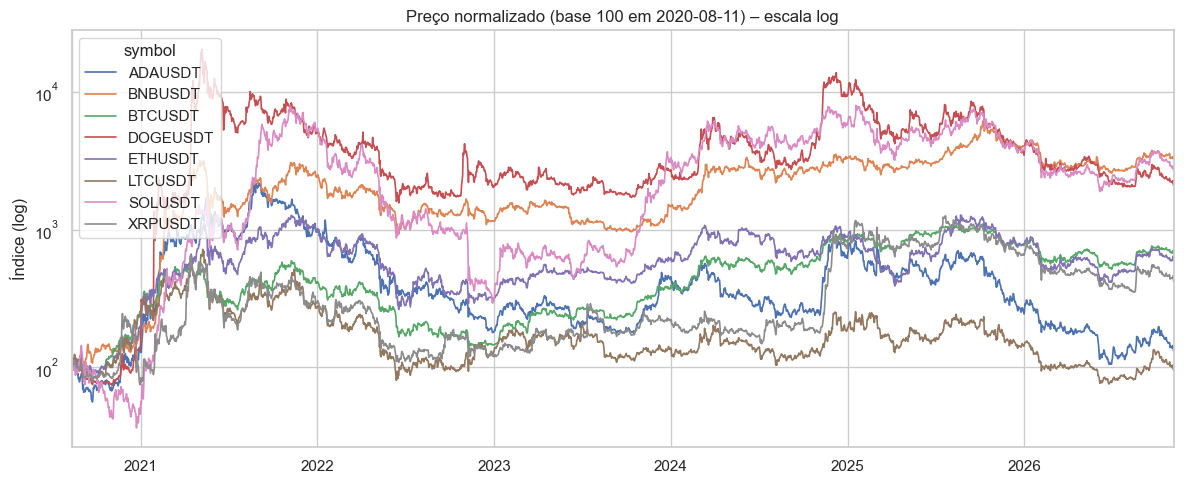

In [5]:
precos = klines.pivot(index="date", columns="symbol", values="close")
inicio_comum = precos.dropna().index.min()
base100 = precos.loc[inicio_comum:].div(precos.loc[inicio_comum]) * 100

fig, ax = plt.subplots(figsize=(12, 5))
base100.plot(ax=ax, logy=True, lw=1.2)
ax.set_title(f"Preço normalizado (base 100 em {inicio_comum.date()}) – escala log")
ax.set_ylabel("Índice (log)"); ax.set_xlabel("")
salvar("01_precos_base100")

### 4.2 Distribuição dos retornos diários
Retornos de cripto têm **caudas pesadas**: dias de ±10% são muito mais frequentes do que uma distribuição normal preveria.

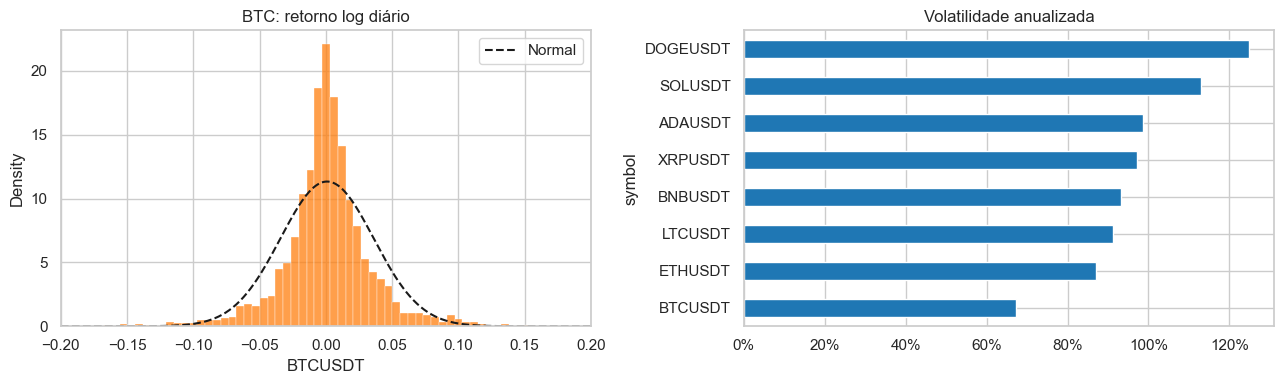

,count,mean,std,min,25%,50%,75%,max,curtose,assimetria
symbol,,,,,,,,,,
ADAUSDT,"3,125.0000",-0.0001,0.0516,-0.5331,-0.0259,-0.0008,0.0234,0.5432,10.2081,0.1491
BNBUSDT,"3,287.0000",0.0019,0.0487,-0.5823,-0.0164,0.0013,0.0193,0.5324,21.9100,0.3298
BTCUSDT,"3,368.0000",0.0009,0.0352,-0.5026,-0.0138,0.0005,0.0153,0.2030,16.0441,-0.9545
DOGEUSDT,"2,681.0000",0.0011,0.0653,-0.4851,-0.0229,-0.0007,0.0195,1.5941,144.5526,6.3265
ETHUSDT,"3,368.0000",0.0006,0.0455,-0.5905,-0.0194,0.0006,0.0209,0.2338,12.1621,-0.8747
LTCUSDT,"3,250.0000",-0.0005,0.0477,-0.4867,-0.0218,0.0000,0.0220,0.2849,9.3196,-0.6027
SOLUSDT,"2,278.0000",0.0015,0.0591,-0.5490,-0.0285,-0.0004,0.0293,0.3776,8.5194,-0.2083
XRPUSDT,"3,108.0000",0.0001,0.0509,-0.5387,-0.0204,-0.0004,0.0187,0.5487,18.9129,0.5901


In [6]:
retornos = np.log(precos).diff()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(retornos["BTCUSDT"].dropna(), bins=120, stat="density", ax=axes[0], color="tab:orange")
x = np.linspace(-0.2, 0.2, 300); m, s = retornos["BTCUSDT"].mean(), retornos["BTCUSDT"].std()
axes[0].plot(x, np.exp(-(x - m) ** 2 / (2 * s ** 2)) / (s * np.sqrt(2 * np.pi)), "k--", label="Normal")
axes[0].set_xlim(-0.2, 0.2); axes[0].legend(); axes[0].set_title("BTC: retorno log diário")

vol_anual = retornos.std() * np.sqrt(365)
vol_anual.sort_values().plot.barh(ax=axes[1], color="tab:blue")
axes[1].set_title("Volatilidade anualizada"); axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
salvar("02_retornos_volatilidade")

retornos.describe().T.assign(curtose=retornos.kurt(), assimetria=retornos.skew())

### 4.3 Correlação entre as moedas
As moedas andam muito juntas: o **regime do Bitcoin** é um atributo importante para as demais.

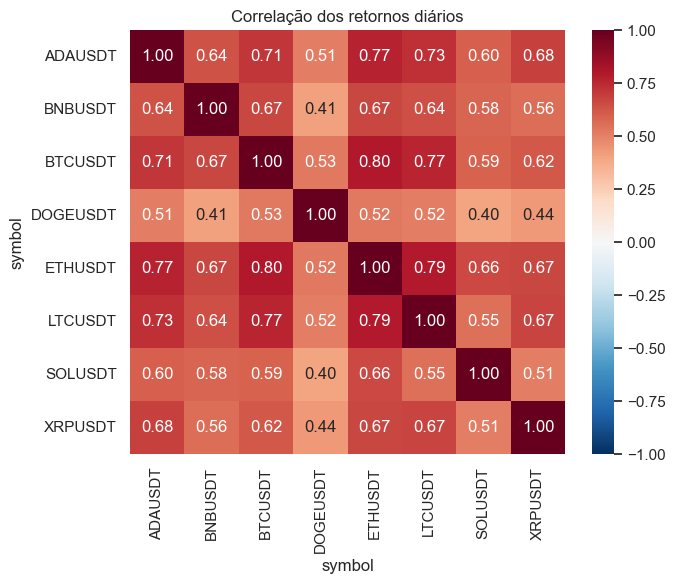

In [7]:
plt.figure(figsize=(7, 6))
sns.heatmap(retornos.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlação dos retornos diários")
salvar("03_correlacao_moedas")

## 5. Engenharia de atributos e variável-alvo

Implementada em `src/features.py`. Para cada moeda são calculados **26 atributos**, todos usando apenas dados disponíveis até o fechamento do dia *t*:

| Grupo | Atributos |
|---|---|
| Momentum | retornos de 1, 3, 7, 14 e 30 dias |
| Volatilidade | desvio-padrão 7d e 30d, razão entre eles, amplitude do dia |
| Tendência | distância do preço às médias móveis de 7, 30 e 90 dias; SMA7/SMA30 |
| Osciladores | RSI(14), histograma do MACD, %B de Bollinger |
| Topos/fundos | queda desde a máxima de 90d, distância à mínima de 30d |
| Volume | volume relativo à média de 30d, proporção de compras agressoras (*taker buy*), nº de negócios relativo |
| Mercado | retorno 7d/30d, distância à SMA30 e volatilidade do **BTC** |

Os atributos são **relativos** (retornos, razões), e não preços absolutos. Assim, um único modelo pode ser treinado com todas as moedas juntas: são mais exemplos e o modelo generaliza melhor.

In [8]:
df = montar_dataset(klines, horizonte=HORIZONTE)
df = df.dropna(subset=COLUNAS_FEATURES).reset_index(drop=True)   # remove o "aquecimento" das janelas (90 dias)
print(df.shape)
df[["date", "symbol", "close"] + COLUNAS_FEATURES[:6] + ["retorno_futuro", "alvo"]].tail()

(23761, 40)


,date,symbol,close,ret_1d,ret_3d,ret_7d,ret_14d,ret_30d,vol_7d,retorno_futuro,alvo
23756,2026-11-06,DOGEUSDT,0.0724,0.0175,-0.0377,-0.0476,-0.0823,-0.2065,0.0352,NaN,NaN
23757,2026-11-06,ETHUSDT,"2,238.6700",0.0003,-0.0160,-0.0031,-0.0644,-0.1396,0.0424,NaN,NaN
23758,2026-11-06,LTCUSDT,52.6000,0.0186,-0.0318,-0.0630,-0.0851,-0.2286,0.0405,NaN,NaN
23759,2026-11-06,SOLUSDT,90.1300,0.0089,-0.0295,-0.0670,-0.1320,-0.2549,0.0315,NaN,NaN
23760,2026-11-06,XRPUSDT,1.1790,-0.0236,-0.0796,-0.0638,-0.0938,-0.1870,0.0342,NaN,NaN


### 5.1 Balanceamento do alvo
O alvo é praticamente balanceado (~50%), mas varia bastante entre anos de alta (*bull*) e de baixa (*bear*). Essa **não estacionariedade** é o principal desafio do problema.

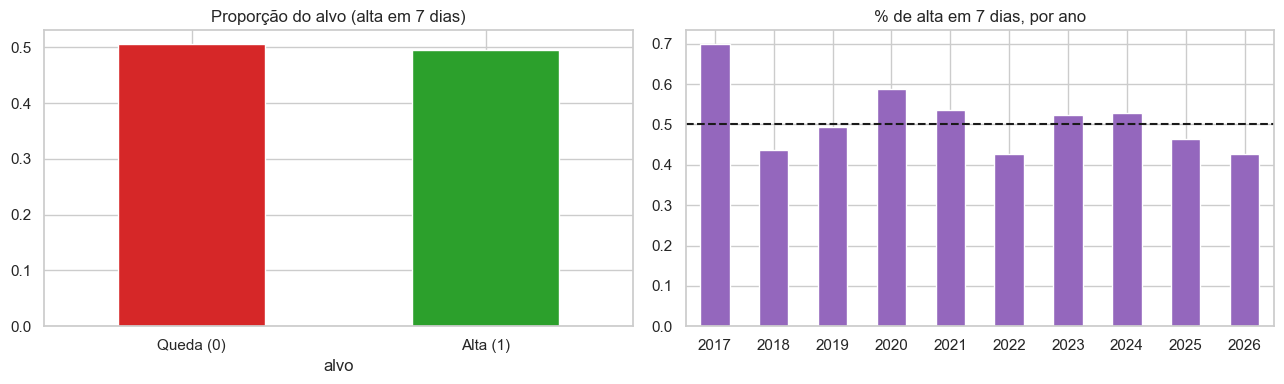

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["alvo"].value_counts(normalize=True).rename({0.0: "Queda (0)", 1.0: "Alta (1)"}).plot.bar(ax=axes[0], color=["tab:red", "tab:green"], rot=0)
axes[0].set_title(f"Proporção do alvo (alta em {HORIZONTE} dias)")
df.groupby(df["date"].dt.year)["alvo"].mean().plot.bar(ax=axes[1], color="tab:purple", rot=0)
axes[1].axhline(0.5, color="k", ls="--"); axes[1].set_title("% de alta em 7 dias, por ano"); axes[1].set_xlabel("")
salvar("04_balanceamento_alvo")

### 5.2 Relação dos atributos com o alvo
Taxa de alta futura por **decil** de alguns atributos. Se a curva fosse plana, o atributo não teria informação.

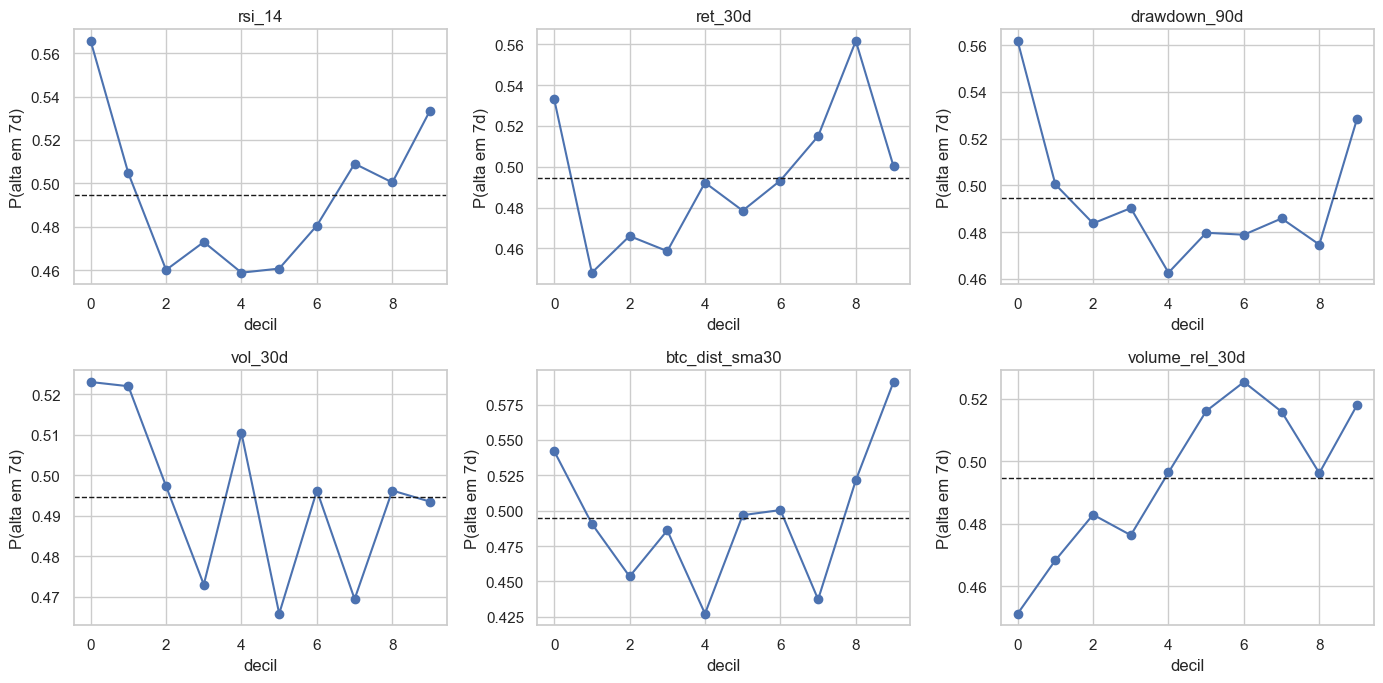

In [10]:
sel = ["rsi_14", "ret_30d", "drawdown_90d", "vol_30d", "btc_dist_sma30", "volume_rel_30d"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
d = df.dropna(subset=["alvo"])
for ax, c in zip(axes.flat, sel):
    dec = pd.qcut(d[c], 10, labels=False, duplicates="drop")
    d.groupby(dec)["alvo"].mean().plot(ax=ax, marker="o")
    ax.axhline(d["alvo"].mean(), color="k", ls="--", lw=1)
    ax.set_title(c); ax.set_xlabel("decil"); ax.set_ylabel("P(alta em 7d)")
salvar("05_atributos_vs_alvo")

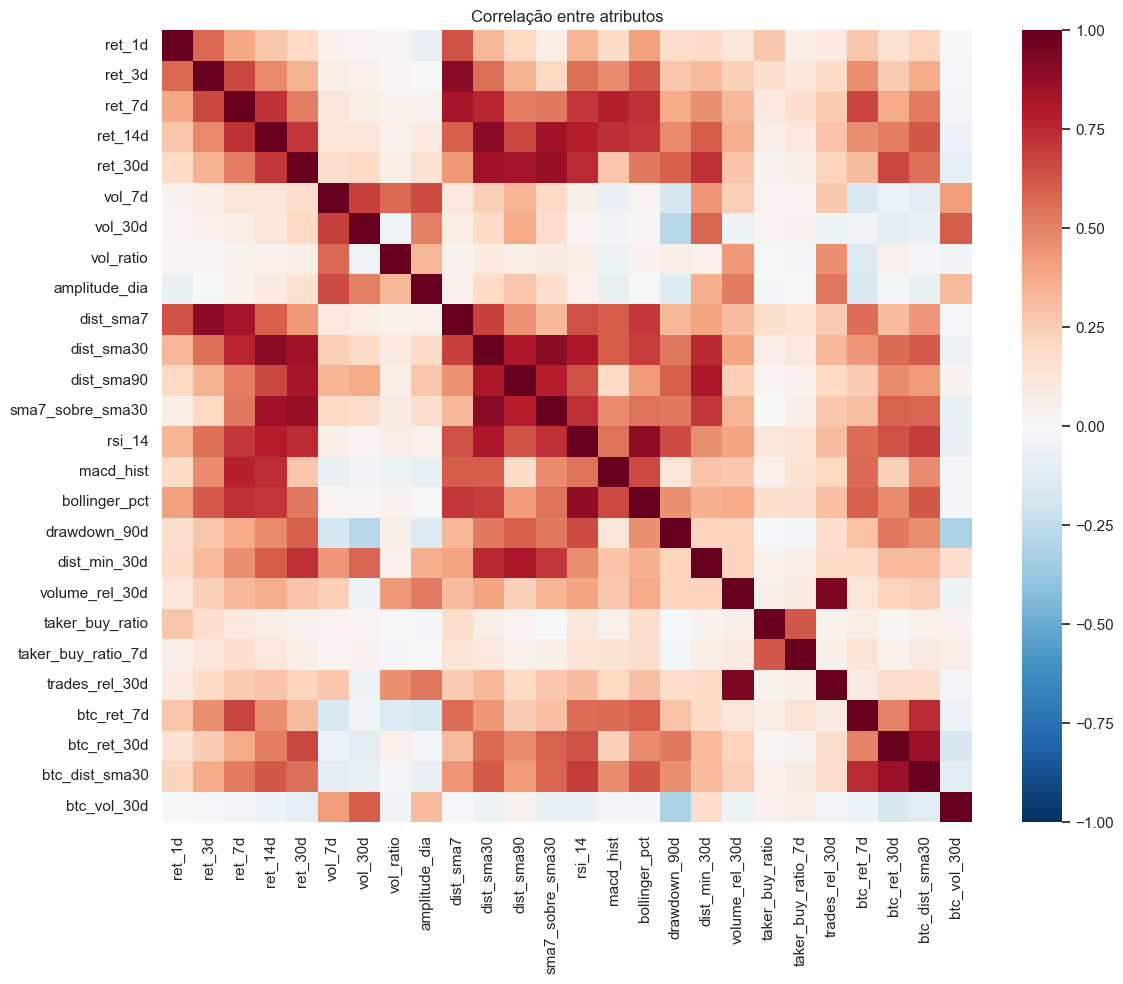

In [11]:
plt.figure(figsize=(12, 10))
sns.heatmap(df[COLUNAS_FEATURES].corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlação entre atributos")
salvar("06_correlacao_atributos")

## 6. Divisão temporal dos dados

Em séries temporais **não se pode embaralhar** os dados: o modelo seria treinado com o futuro e avaliado no passado, e as métricas ficariam artificialmente otimistas.

| Conjunto | Período | Uso |
|---|---|---|
| Treino | início → 2023 | ajustar os modelos |
| Validação | 2024 | comparar modelos e escolher limiares de compra/venda |
| Teste | 2025 → hoje | **avaliação final, usada uma única vez** |

**Purga (*purging*):** o alvo do dia *t* usa o preço de *t+7*. Por isso os últimos 7 dias antes de cada corte são descartados, para que o alvo do treino não "invada" o período seguinte.

In [12]:
CORTE_VAL, CORTE_TESTE = pd.Timestamp("2024-01-01"), pd.Timestamp("2025-01-01")
purga = pd.Timedelta(days=HORIZONTE)

treino = df[df["date"] < CORTE_VAL - purga].dropna(subset=["alvo"])
valid  = df[(df["date"] >= CORTE_VAL) & (df["date"] < CORTE_TESTE - purga)].dropna(subset=["alvo"])
teste_completo = df[df["date"] >= CORTE_TESTE].copy()          # inclui os últimos dias (sem alvo ainda) para o backtest/sinal
teste = teste_completo.dropna(subset=["alvo"])

X_tr, y_tr = treino[COLUNAS_FEATURES], treino["alvo"]
X_va, y_va = valid[COLUNAS_FEATURES], valid["alvo"]
X_te, y_te = teste[COLUNAS_FEATURES], teste["alvo"]

pd.DataFrame({
    "linhas": [len(treino), len(valid), len(teste)],
    "inicio": [treino.date.min().date(), valid.date.min().date(), teste.date.min().date()],
    "fim": [treino.date.max().date(), valid.date.max().date(), teste.date.max().date()],
    "% alta": [y_tr.mean(), y_va.mean(), y_te.mean()],
}, index=["treino", "validação", "teste"])

,linhas,inicio,fim,% alta
treino,15377,2017-11-14,2023-12-24,0.5061
validação,2872,2024-01-01,2024-12-24,0.5212
teste,5344,2025-01-01,2026-10-30,0.4461


## 7. Modelagem

Modelos comparados, do mais simples ao mais complexo:
1. **Baseline – classe majoritária:** sempre prevê a classe mais comum no treino (AUC = 0,5 por definição).
2. **Regressão Logística** (com padronização): modelo linear e interpretável.
3. **Random Forest:** conjunto de árvores; captura não linearidades.
4. **XGBoost:** *gradient boosting*, em geral o mais forte em dados tabulares.

Os hiperparâmetros são deliberadamente **conservadores** (árvores rasas, folhas grandes, regularização forte), porque o sinal é fraco e o risco de *overfitting* é alto.

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

def criar_modelos():
    return {
        "Baseline (majoritária)": DummyClassifier(strategy="most_frequent"),
        "Regressão Logística": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)),
        "Random Forest": RandomForestClassifier(n_estimators=400, max_depth=6, min_samples_leaf=50,
                                                n_jobs=-1, random_state=SEED),
        "XGBoost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8,
                                 colsample_bytree=0.8, min_child_weight=20, reg_lambda=5,
                                 random_state=SEED, eval_metric="logloss"),
    }

def avaliar(y, p, limiar=0.5):
    yp = (p >= limiar).astype(int)
    return {"AUC": roc_auc_score(y, p) if len(np.unique(p)) > 1 else 0.5,
            "Acurácia": accuracy_score(y, yp), "Precisão": precision_score(y, yp, zero_division=0),
            "Recall": recall_score(y, yp, zero_division=0), "F1": f1_score(y, yp, zero_division=0)}

modelos = criar_modelos()
res_val = {}
for nome, m in modelos.items():
    m.fit(X_tr, y_tr)
    res_val[nome] = avaliar(y_va, m.predict_proba(X_va)[:, 1])
pd.DataFrame(res_val).T.style.format("{:.3f}").highlight_max(axis=0, color="#c6efce").set_caption("Validação (2024)")

,AUC,Acurácia,Precisão,Recall,F1
Baseline (majoritária),0.500,0.521,0.521,1.000,0.685
Regressão Logística,0.538,0.534,0.563,0.476,0.516
Random Forest,0.554,0.525,0.553,0.460,0.502
XGBoost,0.550,0.553,0.597,0.435,0.503


### 7.1 Validação cruzada temporal (robustez)
Uma única janela de validação pode ser sorte. Aqui fazemos uma **validação cruzada com janela expansível** (`TimeSeriesSplit`) dentro do período de treino + validação: cada *fold* treina no passado e testa no bloco seguinte.

In [14]:
from sklearn.model_selection import TimeSeriesSplit

dev = pd.concat([treino, valid]).sort_values("date")
datas = np.sort(dev["date"].unique())
tss = TimeSeriesSplit(n_splits=5)
linhas = []
for k, (i_tr, i_te) in enumerate(tss.split(datas)):
    d_tr = datas[i_tr][:-HORIZONTE]                      # purga no fim do treino
    a, b = dev[dev.date.isin(d_tr)], dev[dev.date.isin(datas[i_te])]
    for nome, m in criar_modelos().items():
        if nome.startswith("Baseline"):
            continue
        m.fit(a[COLUNAS_FEATURES], a["alvo"])
        linhas.append({"fold": k + 1, "periodo_teste": f"{pd.Timestamp(datas[i_te][0]).date()} → {pd.Timestamp(datas[i_te][-1]).date()}",
                       "modelo": nome, "AUC": roc_auc_score(b["alvo"], m.predict_proba(b[COLUNAS_FEATURES])[:, 1])})
cv = pd.DataFrame(linhas)
display(cv.pivot(index=["fold", "periodo_teste"], columns="modelo", values="AUC").style.format("{:.3f}"))
cv.groupby("modelo")["AUC"].agg(["mean", "std"]).sort_values("mean", ascending=False)

,modelo,Random Forest,Regressão Logística,XGBoost
fold,periodo_teste,,,
1,2019-01-24 → 2020-03-29,0.441,0.478,0.455
2,2020-03-30 → 2021-06-03,0.485,0.500,0.482
3,2021-06-04 → 2022-08-08,0.552,0.509,0.532
4,2022-08-09 → 2023-10-13,0.512,0.506,0.533
5,2023-10-14 → 2024-12-24,0.575,0.536,0.588


,mean,std
modelo,,
XGBoost,0.5181,0.0517
Random Forest,0.5131,0.0532
Regressão Logística,0.5059,0.0208


### 7.2 Escolha do modelo e dos limiares (somente com a validação)
O modelo final é o de **maior AUC média na validação cruzada**. Os limiares de compra/venda são escolhidos pelo **maior Sharpe no período de validação**, testando uma grade de valores. O conjunto de teste continua intocado.

In [15]:
NOME_FINAL = cv.groupby("modelo")["AUC"].mean().idxmax()
print("Modelo escolhido:", NOME_FINAL)
modelo = criar_modelos()[NOME_FINAL].fit(X_tr, y_tr)

val_bt = valid.copy(); val_bt["prob"] = modelo.predict_proba(X_va)[:, 1]
grade = []
for lc in [0.50, 0.52, 0.54, 0.56, 0.58, 0.60]:
    for lv in [0.40, 0.42, 0.44, 0.46, 0.48, 0.50]:
        if lv > lc:
            continue
        r = est.resumo(est.simular(val_bt, "prob", lc, lv)).loc["CARTEIRA (média)"]
        grade.append({"limiar_compra": lc, "limiar_venda": lv, "sharpe": r.estrat_sharpe,
                      "retorno": r.estrat_retorno, "max_dd": r.estrat_max_dd, "tempo_posicionado": r.tempo_posicionado})
grade = pd.DataFrame(grade).sort_values("sharpe", ascending=False)
LIMIAR_COMPRA, LIMIAR_VENDA = grade.iloc[0][["limiar_compra", "limiar_venda"]]
print(f"Limiares escolhidos na validação: COMPRAR se p ≥ {LIMIAR_COMPRA:.2f} | VENDER se p ≤ {LIMIAR_VENDA:.2f}")
grade.head(8)

Modelo escolhido: XGBoost


Limiares escolhidos na validação: COMPRAR se p ≥ 0.56 | VENDER se p ≤ 0.46


,limiar_compra,limiar_venda,sharpe,retorno,max_dd,tempo_posicionado
21,0.5600,0.4600,3.6020,2.5171,-0.1679,0.3447
29,0.5800,0.5000,3.5661,1.9686,-0.1383,0.2378
35,0.6000,0.5000,3.4821,1.7040,-0.1184,0.2086
23,0.5600,0.5000,3.4563,2.0410,-0.1507,0.2803
27,0.5800,0.4600,3.3605,2.0370,-0.1628,0.3033
20,0.5600,0.4400,3.3579,2.3752,-0.1679,0.3861
22,0.5600,0.4800,3.3515,2.0520,-0.1679,0.3085
28,0.5800,0.4800,3.3051,1.8677,-0.1563,0.2674


### 7.3 Re-treino final
Com o modelo e os limiares definidos, o modelo é re-treinado com **treino + validação** (dados mais recentes ajudam em séries não estacionárias) e só então aplicado ao teste.

In [16]:
dev_final = df[df["date"] < CORTE_TESTE - purga].dropna(subset=["alvo"])
modelo_final = criar_modelos()[NOME_FINAL].fit(dev_final[COLUNAS_FEATURES], dev_final["alvo"])
print(f"{NOME_FINAL} re-treinado com {len(dev_final):,} linhas ({dev_final.date.min().date()} → {dev_final.date.max().date()})")

XGBoost re-treinado com 18,305 linhas (2017-11-14 → 2024-12-24)


## 8. Avaliação técnica no conjunto de teste (2025 → hoje)

In [17]:
res_te, probs_te = {}, {}
for nome, m in criar_modelos().items():
    m.fit(dev_final[COLUNAS_FEATURES], dev_final["alvo"])
    probs_te[nome] = m.predict_proba(X_te)[:, 1]
    res_te[nome] = avaliar(y_te, probs_te[nome])
tab_teste = pd.DataFrame(res_te).T
tab_teste.style.format("{:.3f}").highlight_max(axis=0, color="#c6efce").set_caption("Teste (2025 → hoje)")

,AUC,Acurácia,Precisão,Recall,F1
Baseline (majoritária),0.500,0.446,0.446,1.000,0.617
Regressão Logística,0.532,0.531,0.474,0.473,0.474
Random Forest,0.556,0.546,0.490,0.427,0.456
XGBoost,0.548,0.532,0.480,0.580,0.525


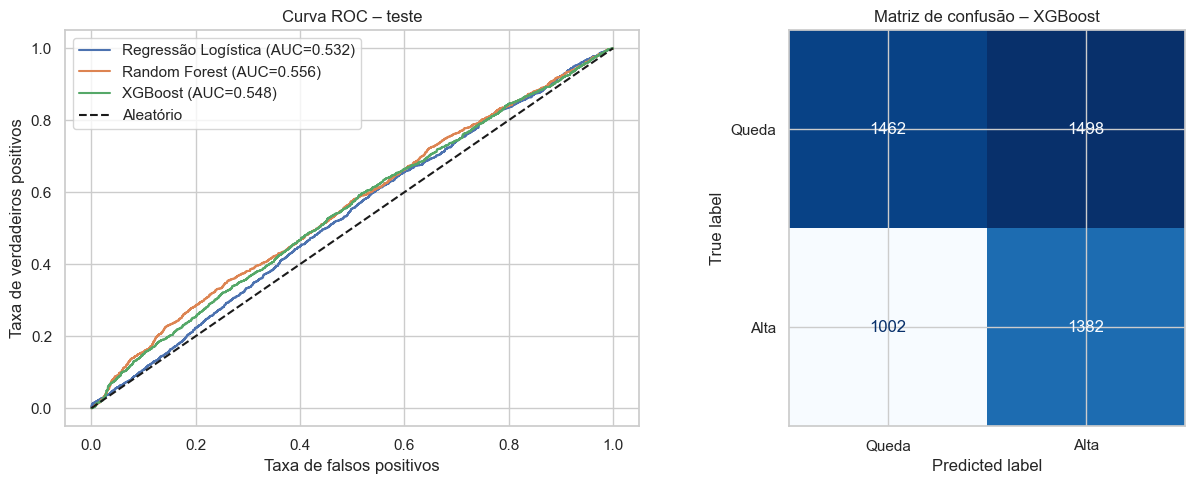

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nome, p in probs_te.items():
    if nome.startswith("Baseline"):
        continue
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[0].plot(fpr, tpr, label=f"{nome} (AUC={roc_auc_score(y_te, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Aleatório"); axes[0].legend(); axes[0].set_title("Curva ROC – teste")
axes[0].set_xlabel("Taxa de falsos positivos"); axes[0].set_ylabel("Taxa de verdadeiros positivos")

p_final = probs_te[NOME_FINAL]
ConfusionMatrixDisplay(confusion_matrix(y_te, (p_final >= 0.5).astype(int)),
                       display_labels=["Queda", "Alta"]).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title(f"Matriz de confusão – {NOME_FINAL}")
salvar("07_roc_confusao_teste")

### 8.1 A probabilidade do modelo é útil? (análise por faixa)
Se o modelo tem valor, quanto **maior a probabilidade prevista**, maior deve ser a taxa real de alta e o retorno médio dos 7 dias seguintes.

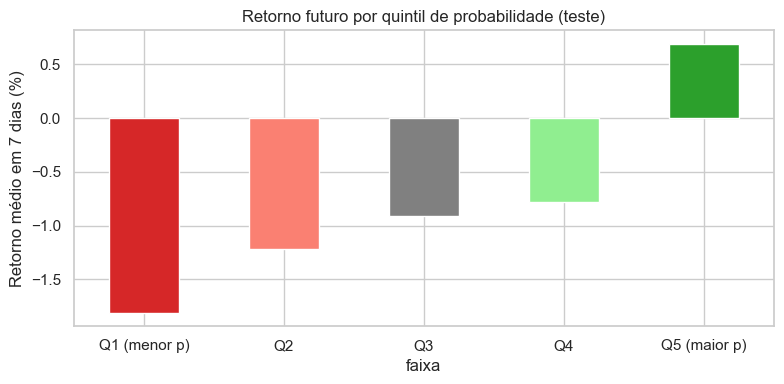

,prob_media,taxa_alta_real,retorno_medio_7d,n
faixa,,,,
Q1 (menor p),0.3825,0.3957,-0.0181,1069
Q2,0.4603,0.4079,-0.0121,1069
Q3,0.5079,0.4551,-0.0091,1068
Q4,0.5470,0.4584,-0.0078,1069
Q5 (maior p),0.6218,0.5136,0.0069,1069


In [19]:
t = teste.assign(prob=p_final)
t["faixa"] = pd.qcut(t["prob"], 5, labels=["Q1 (menor p)", "Q2", "Q3", "Q4", "Q5 (maior p)"])
faixas = t.groupby("faixa", observed=True).agg(prob_media=("prob", "mean"), taxa_alta_real=("alvo", "mean"),
                                               retorno_medio_7d=("retorno_futuro", "mean"), n=("alvo", "size"))
fig, ax = plt.subplots(figsize=(8, 4))
(faixas["retorno_medio_7d"] * 100).plot.bar(ax=ax, color=["tab:red", "salmon", "grey", "lightgreen", "tab:green"], rot=0)
ax.set_ylabel("Retorno médio em 7 dias (%)"); ax.set_title("Retorno futuro por quintil de probabilidade (teste)")
salvar("08_quintis_probabilidade")
faixas

### 8.2 Importância dos atributos
**Importância por permutação** no conjunto de validação: mede quanto a AUC cai quando os valores de um atributo são embaralhados. Ela é mais confiável que a importância interna das árvores.

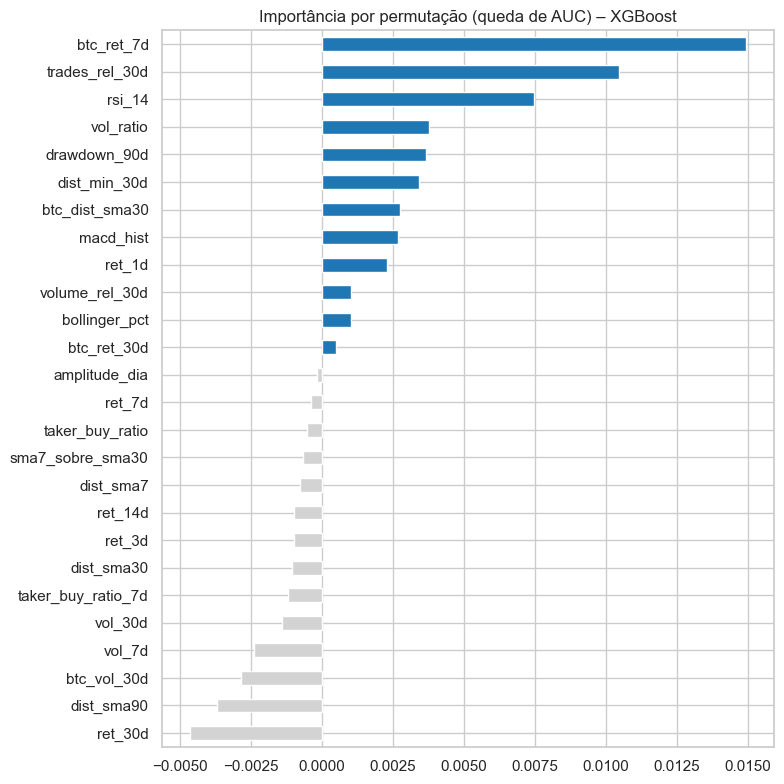

In [20]:
imp = permutation_importance(modelo, X_va, y_va, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=COLUNAS_FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 8))
imp.plot.barh(ax=ax, color=np.where(imp > 0, "tab:blue", "lightgrey"))
ax.set_title(f"Importância por permutação (queda de AUC) – {NOME_FINAL}")
salvar("09_importancia_atributos")

## 9. Avaliação de negócio – backtest no teste

A estratégia (definida em `src/estrategia.py`) opera **só comprada ou em caixa** (sem venda a descoberto), com taxa de 0,1% por operação. Ela é comparada com:
- **Buy & Hold:** comprar no 1º dia do teste e segurar até o fim;
- **Regra simples de tendência:** ficar comprado quando o preço está acima da média móvel de 30 dias (uma estratégia clássica e fácil de explicar);
- **Estratégia aleatória com a mesma exposição:** controla o efeito de simplesmente "ficar menos tempo no mercado" em um período de queda.

In [21]:
bt = teste_completo.copy()
bt["prob"] = modelo_final.predict_proba(bt[COLUNAS_FEATURES])[:, 1]
sim = est.simular(bt, "prob", LIMIAR_COMPRA, LIMIAR_VENDA)

# Regra de tendência (SMA30): "prob" = 1 acima da média, 0 abaixo -> COMPRAR / VENDER
bt_sma = bt.assign(prob=(bt["dist_sma30"] > 0).astype(float))
sim_sma = est.simular(bt_sma, "prob", 0.5, 0.5)

tab = est.resumo(sim)
tab["sma30_retorno"] = est.resumo(sim_sma)["estrat_retorno"]
tab["sma30_sharpe"] = est.resumo(sim_sma)["estrat_sharpe"]
fmt = {c: "{:.1%}" for c in tab.columns if "retorno" in c or "dd" in c or "tempo" in c}
fmt.update({c: "{:.2f}" for c in tab.columns if "sharpe" in c})
tab.style.format(fmt).set_caption(f"Backtest {bt.date.min().date()} → {bt.date.max().date()} | ML: {NOME_FINAL}")

,estrat_retorno,bh_retorno,estrat_sharpe,bh_sharpe,estrat_max_dd,bh_max_dd,tempo_posicionado,n_operacoes,sma30_retorno,sma30_sharpe
moeda,,,,,,,,,,
ADAUSDT,16.5%,-80.0%,0.44,-0.46,-72.4%,-87.3%,49.8%,52,-78.8%,-1.44
BNBUSDT,51.9%,-2.0%,0.81,0.22,-45.0%,-58.2%,48.4%,50,0.8%,0.19
BTCUSDT,-9.9%,-19.8%,-0.05,-0.06,-52.8%,-53.0%,41.5%,52,-15.8%,-0.25
DOGEUSDT,-51.9%,-77.7%,-0.31,-0.59,-63.3%,-83.4%,52.4%,54,-26.2%,-0.10
ETHUSDT,11.0%,-33.4%,0.36,0.02,-46.1%,-67.6%,39.9%,60,66.5%,0.84
LTCUSDT,-11.9%,-50.0%,0.06,-0.21,-56.0%,-70.1%,43.0%,44,-44.1%,-0.41
SOLUSDT,76.9%,-53.6%,0.84,-0.17,-39.1%,-76.3%,47.0%,58,3.7%,0.26
XRPUSDT,17.6%,-49.5%,0.42,-0.13,-58.3%,-72.0%,38.8%,50,-42.6%,-0.44
CARTEIRA (média),16.0%,-46.6%,0.40,-0.24,-44.3%,-66.7%,45.1%,420,-21.6%,-0.27


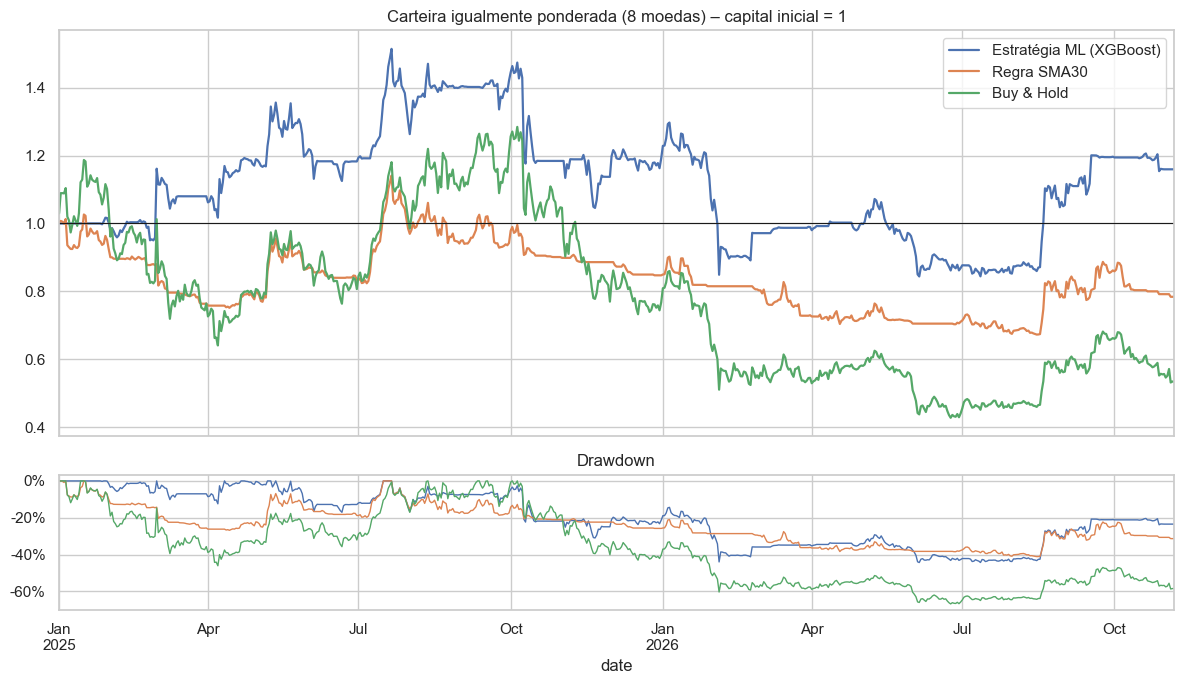

In [22]:
cart_ml, cart_sma = est.carteira(sim), est.carteira(sim_sma)
curvas = pd.DataFrame({
    f"Estratégia ML ({NOME_FINAL})": (1 + cart_ml["ret_estrategia"]).cumprod(),
    "Regra SMA30": (1 + cart_sma["ret_estrategia"]).cumprod(),
    "Buy & Hold": (1 + cart_ml["ret_buyhold"]).cumprod(),
})
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
curvas.plot(ax=axes[0], lw=1.6); axes[0].axhline(1, color="k", lw=0.8)
axes[0].set_title("Carteira igualmente ponderada (8 moedas) – capital inicial = 1")
(curvas / curvas.cummax() - 1).plot(ax=axes[1], legend=False, lw=1); axes[1].set_title("Drawdown")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
salvar("10_backtest_carteira")

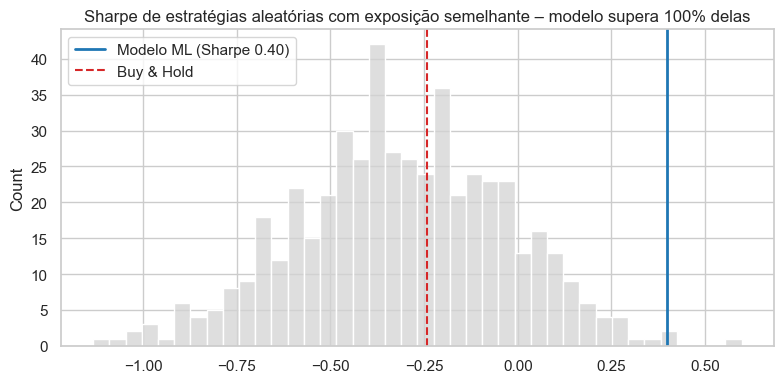

In [23]:
# Teste de "sorte": 500 estratégias aleatórias que ficam posicionadas o MESMO % do tempo que o modelo
rng = np.random.default_rng(SEED)
exposicao = sim["posicao"].mean()
rets = sim.pivot(index="date", columns="symbol", values="ret_ativo").fillna(0)
n_dias, n_moedas = rets.shape
n_blocos = int(np.ceil(n_dias / 7))
sharpes_aleat = []
for _ in range(500):
    # decide aleatoriamente, semana a semana e moeda a moeda, se fica comprado (prob. = exposição do modelo)
    blocos = (rng.random((n_blocos, n_moedas)) < exposicao).astype(float)
    pos = pd.DataFrame(np.repeat(blocos, 7, axis=0)[:n_dias], index=rets.index, columns=rets.columns)
    custo = pos.diff().abs().fillna(pos) * est.TAXA
    r = (pos * rets - custo).mean(axis=1)
    sharpes_aleat.append(r.mean() / r.std() * np.sqrt(365))
sharpe_ml = tab.loc["CARTEIRA (média)", "estrat_sharpe"]
pct = (np.array(sharpes_aleat) < sharpe_ml).mean()

plt.figure(figsize=(8, 4))
sns.histplot(sharpes_aleat, bins=40, color="lightgrey")
plt.axvline(sharpe_ml, color="tab:blue", lw=2, label=f"Modelo ML (Sharpe {sharpe_ml:.2f})")
plt.axvline(tab.loc["CARTEIRA (média)", "bh_sharpe"], color="tab:red", ls="--", label="Buy & Hold")
plt.title(f"Sharpe de estratégias aleatórias com exposição semelhante – modelo supera {pct:.0%} delas")
plt.legend(); salvar("11_teste_aleatorio")

## 10. Sinal atual

Probabilidade de alta nos próximos 7 dias e sinal para o último dia disponível. O sinal **MANTER** significa "continue na posição em que você já está".

In [24]:
ultimo = sim.sort_values("date").groupby("symbol").tail(1)[["date", "symbol", "close", "prob", "sinal", "posicao"]]
ultimo = ultimo.rename(columns={"prob": "P(alta 7d)", "posicao": "posição_estratégia"}).set_index("symbol")
print(f"Limiares: COMPRAR se p ≥ {LIMIAR_COMPRA:.2f} | VENDER se p ≤ {LIMIAR_VENDA:.2f}  (posição 1 = comprado, 0 = caixa)")
ultimo.style.format({"close": "{:,.4f}", "P(alta 7d)": "{:.1%}", "posição_estratégia": "{:.0f}"})

Limiares: COMPRAR se p ≥ 0.56 | VENDER se p ≤ 0.46  (posição 1 = comprado, 0 = caixa)


,date,close,P(alta 7d),sinal,posição_estratégia
symbol,,,,,
DOGEUSDT,2026-11-06 00:00:00,0.0724,46.3%,MANTER,0
LTCUSDT,2026-11-06 00:00:00,52.6000,43.2%,VENDER,0
ETHUSDT,2026-11-06 00:00:00,"2,238.6700",43.9%,VENDER,0
BTCUSDT,2026-11-06 00:00:00,"75,844.0000",45.8%,VENDER,0
BNBUSDT,2026-11-06 00:00:00,693.6700,49.9%,MANTER,0
ADAUSDT,2026-11-06 00:00:00,0.1841,50.8%,MANTER,0
SOLUSDT,2026-11-06 00:00:00,90.1300,45.2%,VENDER,0
XRPUSDT,2026-11-06 00:00:00,1.1790,48.6%,MANTER,0


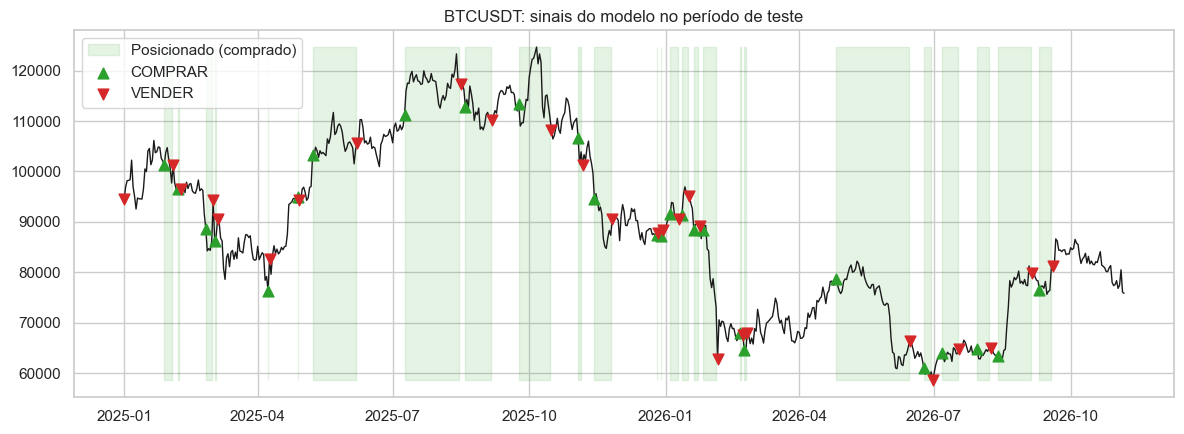

In [25]:
# Histórico de sinais para uma moeda (mude a variável MOEDA)
MOEDA = "BTCUSDT"
g = sim[sim.symbol == MOEDA]
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(g["date"], g["close"], color="k", lw=1)
ax.fill_between(g["date"], g["close"].min(), g["close"].max(), where=g["posicao"] > 0, color="tab:green", alpha=0.12, label="Posicionado (comprado)")
for s, cor, mk in [("COMPRAR", "tab:green", "^"), ("VENDER", "tab:red", "v")]:
    mud = g[(g["sinal"] == s) & (g["posicao"].diff() != 0)]
    ax.scatter(mud["date"], mud["close"], color=cor, marker=mk, s=60, label=s, zorder=3)
ax.set_title(f"{MOEDA}: sinais do modelo no período de teste"); ax.legend(loc="upper left")
salvar(f"12_sinais_{MOEDA}")

## 11. Conclusões, limitações e próximos passos

> Números da execução com dados até **06/11/2026** (teste: 01/01/2025 → 30/10/2026). Ao re-executar com dados novos, revise este texto.

### Principais resultados
| | Valor |
|---|---|
| Modelo escolhido (maior AUC média na validação cruzada temporal) | **XGBoost** |
| AUC no teste (XGBoost / Random Forest / Reg. Logística / Baseline) | 0,548 / 0,556 / 0,532 / 0,500 |
| Retorno médio em 7d: quintil de **menor** vs **maior** probabilidade | −1,8% vs +0,7% |
| Carteira: Estratégia ML vs Buy & Hold vs Regra SMA30 (retorno total) | **+16%** vs −47% vs −22% |
| Sharpe: Estratégia ML vs Buy & Hold | 0,40 vs −0,24 |
| Queda máxima (*max drawdown*): Estratégia ML vs Buy & Hold | −44% vs −67% |
| Tempo posicionado / nº de operações (8 moedas, ~22 meses) | 45% / 420 |

### Respostas às perguntas de negócio
1. **Há informação preditiva?** Sim, mas **fraca**. A AUC de ~0,55 está dentro do esperado para mercados competitivos. O valor do modelo não está em "acertar" cada dia, e sim em **ordenar os momentos**: os dias com maior probabilidade prevista tiveram retorno futuro médio claramente melhor que os de menor probabilidade.
2. **Reduz risco?** Sim, neste período. A estratégia ficou fora do mercado em boa parte das quedas: perda máxima de −44% contra −67% do Buy & Hold, com Sharpe positivo. **Atenção:** o teste caiu em um mercado de baixa (Buy & Hold −47%), e boa parte do ganho vem de *ficar em caixa*. Por isso comparamos com 500 estratégias aleatórias com a mesma exposição, e o modelo superou praticamente todas. A vantagem não é só "ficar menos tempo comprado".
3. **Atributos mais relevantes:** ver a importância por permutação. A EDA mostra relações **não lineares em formato de U** (RSI, queda desde o topo): os extremos, tanto sobrevenda quanto sobrecompra forte, têm maior chance de alta. Isso explica por que modelos de árvore superaram a regressão logística.
4. **Custos:** o backtest já desconta 0,1% por operação. A zona MANTER (entre os limiares) evita trocas excessivas.

### Ressalvas importantes (honestidade estatística)
- Na validação cruzada temporal, os *folds* mais antigos (2019–2021) tiveram **AUC abaixo de 0,5**. O sinal não é estável em todos os regimes de mercado.
- O desempenho por moeda é desigual. BTC e DOGE tiveram retorno negativo com a estratégia, embora melhor que o Buy & Hold.
- Um único período de teste não prova que a estratégia funcionaria no futuro.

### Comunicação para cada público
- **Equipe de dados:** divisão temporal com purga, validação cruzada temporal, limiares escolhidos fora do teste e teste contra estratégias aleatórias com a mesma exposição.
- **Negócio:** o modelo é uma **ferramenta de gestão de risco** (quando ficar fora do mercado), não uma máquina de previsão de preços.

### Limitações
- O período de teste é um único regime de mercado. Resultados podem mudar em mercados de alta.
- O modelo não considera notícias, dados on-chain, sentimento ou fatores macroeconômicos.
- O backtest ignora *slippage* e impostos, e supõe execução no preço de fechamento.
- Há poucas moedas, e todas sobreviveram até hoje (viés de sobrevivência).

### Próximos passos
- Velas de 4h/1h e horizontes diferentes (3, 14 dias).
- Atributos de sentimento (Fear & Greed Index), *funding rate* de futuros e dados on-chain.
- Otimização de hiperparâmetros com validação *walk-forward* e re-treino periódico.
- Formular como **regressão** do retorno futuro ou como problema de 3 classes (alta forte / lateral / queda forte).